# Lecture 23 - Quiz, and Introduction to Parallel Programming

We will start with a quiz based off of the material from homework 8, and the past few weeks worth of lecture material. All students will have 10 minutes to complete the quiz, and the quiz will start promptly at 9:05 AM at the start of class. Please bring a pencil or pen for the quiz.

Next, we will begin our discussion of parallel programming methods, which may be useful for some of your course projects.

Let's say you want to empty a tank that full of water. If I give you one water pipe, you can connected to the bottom of the tank to let the water out. If I give you another water pipe, using both of the pipes will empty the tank in only half of the time. The more water pipes you can connected to the bottom of the tank, the faster you can empty it. The similar thing exist in modern computers as well. Most of our computers these days have a multi-core processor design, which means that we can process the tasks in parallel fashion like using multiple pipes to drain the tank. 

In this lecture, we will introduce your how to run your Python program in parallel so that we can reduce the time of completing the task. For smaller project, the benefit may not seem obvious. But for some complicated projects, the gain is significantly. For example, if I give you a homework that normally you need to wait for 1 hour until you can tell whether your code is correct or not. If you find something is wrong, and you change your code accordingly. Now it is time to wait another hour to find out whether your modification is proper. At the end, you made changes for 20 times, and spend more than a day to get it right. But if you can run your algorithms in a parallel way, the running time of your code may shrink to 5 min. 20 times modification only cost you less than 2 hours. Now you see why we bother to learn how to run our code faster using the parallelization. 

In addition to the lecture material below, all students also need to download `lec20_module.py` using the command below:
```bash
curl -O https://raw.githubusercontent.com/PsuAstro410/psuastro410.github.io/refs/heads/main/lectures/lec23_module.py
```

### Accepting and submitting

To accept this assignment on Classroom 50 with your GitHub profile enrolled in the class, click on the link \
https://classroom50.org/PsuAstro410/410astro26/assignments/lecture-23/accept \
and follow the steps the webpage prompts.

To submit this assignment, follow the steps in "First time Classroom 50 setup" and "Accepting and Submitting Assignments" on the course webpage:\
https://psuastro410.github.io/tips/github/

### Resources and Acknowledgements

We have used material from the following sources: \
https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter13.00-Parallel-Your-Python.html \
https://blog.pythonlibrary.org/2016/08/02/python-201-a-multiprocessing-tutorial/

# Parallel programming

Let's say you want to empty a tank that full of water. If I give you one water pipe, you can connected to the bottom of the tank to let the water out. If I give you another water pipe, using both of the pipes will empty the tank in only half of the time. The more water pipes you can connected to the bottom of the tank, the faster you can empty it. The similar thing exist in modern computers as well. Most of our computers these days have a multi-core processor design, which means that we can process the tasks in parallel fashion like using multiple pipes to drain the tank. 

In this lecture, we will introduce your how to run your Python program in parallel so that we can reduce the time of completing the task. For smaller project, the benefit may not seem obvious. But for some complicated projects, the gain is significantly. For example, if I give you a homework that normally you need to wait for 1 hour until you can tell whether your code is correct or not. If you find something is wrong, and you change your code accordingly. Now it is time to wait another hour to find out whether your modification is proper. At the end, you made changes for 20 times, and spend more than a day to get it right. But if you can run your algorithms in a parallel way, the running time of your code may shrink to 5 min. 20 times modification only cost you less than 2 hours. Now you see why we bother to learn how to run our code faster using the parallelization. 

In [12]:
# Nice things to have this lecture
import multiprocessing as mp
import numpy as np
import time
from joblib import Parallel, delayed


# Parallel Computing Fundamentals

We now have a working knowledge of Python, and soon we will start to use it to analyze data and numerical analysis. Before we go deeper, we need to cover  **parallel computing** in Python. This means you will be able to run your code simultaneously on multiple cores on your CPU processor (or multiple CPU processors) or increase the speed by taking advantage of the wasted CPU cycles while your program is waiting for external resources (i.e., downloading files, API calls, etc.). The fundamental idea of parallel computing is rooted in doing multiple tasks at the same time to reduce the running time of your program. The following figure illustrates the simple idea of doing parallel computing versus serial computing that we used so far. For example, if you have 1 million data files and need to apply the same operations to each one of them, you can do this one file at each time, or you can do it by multiple files at the same time; or if you are downloading 1 million websites, you can take advantage of downloading 10 at a time to reduce the total time of downloading. Therefore, learning the basics of parallel computing will help you design code that is more efficient.

![parallel-programming](https://pythonnumericalmethods.studentorg.berkeley.edu/_images/13.01.01-parallel_vs_serial.png)

Most of the modern computers are using the multi-core design, which means on a single computing component, there are multiple independent processing units, the so called cores, that are available to do different tasks. For example, on my laptop, there is 1 CPU processor, with 6 physical cores on it (see the following figure), each of this physical cores has two logical cores, which will bring the total number of 12 cores (see the next section when we print out the total number of CPU on your machine).

![Multi-Cores](https://pythonnumericalmethods.studentorg.berkeley.edu/_images/13.01.01-my-hardware.png)

In Python, there are two basic approaches to conduct parallel computing, that is using the **multiprocessing** or **threading** library. Let's first take a look of the differences of process and thread. 

## Process and thread

A **process** is an instance of a program (such as Python interpreter, Jupyter notebook etc.). A process is created by the operating system to run program, and each process has its own memory block. A **thread** is a sub-process that reside within the process. Each process can have multiple threads, that these threads will share the same memory block within the process. Therefore, for multiple threads in a process, due to the shared memory space, the variables or objects are all shared. If you change one variable in one thread, it will change for all the other threads. But things are different in different processes, change one variable in one process will not change the one in other processes. Process and thread both have advantages or disadvantages, and can be used in different tasks to maximize the benefits.

## Python's GIL problem

Python has something called Global Interpreter Lock (GIL) which allow only one native thread to run at a time, it prevents multiple threads from running simultaneously:
![GIL-illistration](https://upload.wikimedia.org/wikipedia/commons/0/09/GIL_description.gif?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=original)

This is because Python was designed before the multi-core processor on the personal computers (this shows you how old the language is). Even though there are workarounds in Python to do multi-threading programming, we will only cover the multiprocessing library in the next section, which we will use most of the time for taking advantage of multi-core parallel computing.  

## Disadvantage of using parallel computing

Of course, there are disadvantages of using parallel computing. Such as, more complicated code, overheads when spawn new processes and maintain the. Thus, if your task is small, using parallel computing will take longer time, since it takes time for the system to initialize new process and maintain them.

# Features of Multiprocessing

## Process class

Let’s try creating a series of processes that call the same function and see how the process class works:

In the class module, we have included the function `doubler`:
```python
def doubler(number):
    """
    A doubling function that can be used by a process
    """
    result = number * 2
    proc = os.getpid()
    print('{0} doubled to {1} by process id: {2}'.format(
        number, result, proc))
```

For this example, we import Process and a doubler function. Inside the function, we double the number that was passed in. We also use Python’s os module to get the current process’s ID (or pid). This will tell us which process is calling the function. 

In the block of code below, we create a series of Processes and start them. The very last loop just calls the join() method on each process, which tells Python to wait for the process to terminate. If you need to stop a process, you can call its terminate() method.

In [2]:
numbers = [5, 10, 15, 20, 25]
procs = []
    
for index, number in enumerate(numbers):
    proc = mp.Process(target=mod.doubler, args=(number,))
    procs.append(proc)
    proc.start()
for proc in procs:
    proc.join()

5 doubled to 10 by process id: 92430
15 doubled to 30 by process id: 92432
10 doubled to 20 by process id: 92431
20 doubled to 40 by process id: 92433
25 doubled to 50 by process id: 92434


Sometimes it’s nicer to have a more human readable name for your process though. Fortunately, the Process class does allow you to access the same of your process. Lets run the same code, except with a different function `doubler_troubler`:
```python
def doubler_troubler(number):
    """
    A doubling function that can be used by a process
    """
    result = number * 2
    proc_name = mp.current_process().name
    print('{0} doubled to {1} by: {2}'.format(
        number, result, proc_name))
```

This time around, we import something extra: current_process. The current_process is basically the same thing as the threading module’s current_thread. We use it to grab the name of the thread that is calling our function. You will note that for the first five processes, we don’t set a name. Then for the sixth, we set the process name to “Test”. Let’s see what we get for output:

In [3]:
numbers = [5, 10, 15, 20, 25]
procs = []
proc = mp.Process(target=mod.doubler_troubler, args=(5,))
for index, number in enumerate(numbers):
    proc = mp.Process(target=mod.doubler_troubler, args=(number,))
    procs.append(proc)
    proc.start()
    
proc = mp.Process(target=mod.doubler_troubler, name='Test', args=(2,))
proc.start()
procs.append(proc)
for proc in procs:
    proc.join()

5 doubled to 10 by: Process-7
15 doubled to 30 by: Process-9
25 doubled to 50 by: Process-11
2 doubled to 4 by: Test
10 doubled to 20 by: Process-8
20 doubled to 40 by: Process-10


The output demonstrates that the multiprocessing module assigns a number to each process as a part of its name by default. Of course, when we specify a name, a number isn’t going to get added to it.

## The Pool Class

The Pool class is used to represent a pool of worker processes. It has methods which can allow you to offload tasks to the worker processes. Let’s look our function `doubler_simple`:
```python
def doubler_simple(number):
    return number * 2
```
Now lets create an instance of Pool and tell it to create three worker processes. Then we use the map method to map a function and an iterable to each process. Finally we print the result, which in this case is actually a list: [10, 20, 40]:

In [4]:
numbers = [5, 10, 20]
pool = mp.Pool(processes=3)
print(pool.map(mod.doubler_simple, numbers))

[10, 20, 40]


You can also get the result of your process in a pool by using the apply_async method:

In [5]:
pool = mp.Pool(processes=3)
result = pool.apply_async(mod.doubler_simple, (25,))
print(result.get(timeout=1))

50


What this allows us to do is actually ask for the result of the process. That is what the get function is all about. It tries to get our result. You will note that we also have a timeout set just in case something happened to the function we were calling. We don’t want it to block indefinitely after all.

## Process Communication

When it comes to communicating between processes, the multiprocessing modules has two primary methods: Queues and Pipes. The Queue implementation is actually both thread and process safe. Let’s take a look at an example of two functions:

```python

def creator(data, q):
    """
    Creates data to be consumed and waits for the consumer
    to finish processing
    """
    print('Creating data and putting it on the queue')
    for item in data:
        
        q.put(item)
        
def my_consumer(q):
    """
    Consumes some data and works on it
    In this case, all it does is double the input
    """
    while True:
        data = q.get()
        print('data found to be processed: {}'.format(data))
        processed = data * 2
        print(processed)
        
        if data is sentinel:
            break

```

Here we just need to import Queue and Process. Then we two functions, one to create data and add it to the queue and the second to consume the data and process it. Adding data to the Queue is done by using the Queue’s put() method whereas getting data from the Queue is done via the get method. 

The chunk of code below creates the Queue object and a couple of Processes and then runs them. You will note that we call join() on our process objects rather than the Queue itself:

In [6]:
q = mp.Queue()
data = [5, 10, 13, -1]
process_one = mp.Process(target=mod.creator, args=(data, q))
process_two = mp.Process(target=mod.my_consumer, args=(q,))
process_one.start()
process_two.start()
    
q.close()
q.join_thread()
process_one.join()
process_two.join()

Creating data and putting it on the queue
data found to be processed: 5
10
data found to be processed: 10
20
data found to be processed: 13
26
data found to be processed: -1
-2


In [7]:
lock = mp.Lock()
items = ['tango', 'foxtrot', 10]
for item in items:
    p = mp.Process(target=mod.printer, args=(item, lock))
    p.start()

AttributeError: module 'lec23_module' has no attribute 'printer'

# Advantages of Multiprocessing

Let's first print out the total number of CPUs that on my machine that can be used for parallel computing.

In [8]:
print(f"Number of cpu: {mp.cpu_count()}")

Number of cpu: 8


Let's use an example to show you how to use multiple cores in one machine to reduce the time of execution time. 

**EXAMPLE:** Generate 10,000,000 random numbers between 0 and 10, and square the number. Store the results in a list. 

## Serial version

In the module, we have the following function:

```python
def random_square(seed):
    np.random.seed(seed)
    random_num = np.random.randint(0, 10)
    return random_num**2
```
Lets run this in serial

In [10]:
t0 = time.time()
results = []
for i in range(10000000): 
    results.append(mod.random_square(i))
t1 = time.time()
print(f'Execution time {t1 - t0} s')

Execution time 27.461665153503418 s


## Parallel version

The simplest way to do parallel computing using the multiprocessing is to use the **Pool** class. There are 4 common methods in the class that we may use often, that is *apply*, *map*, *apply_async* and *map_async*. Have a look of the documentation for the differences, and we will only use *map* function below to parallel the above example. The *map(func, iterable)* function takes in two arguments, and apply the function *func* to each element in the *iterable*, and then collect the results. 

In [11]:
t0 = time.time()
n_cpu = mp.cpu_count()

pool = mp.Pool(processes=n_cpu)
results = [pool.map(mod.random_square, range(10000000))]
t1 = time.time()
print(f'Execution time {t1 - t0} s')

Execution time 6.025475978851318 s


We can see that using the above parallel version of the code, we reduce the run time from ~38 s to ~7 s. This is a big gain in speed, especially if we have a heavy computation, it will reduce a lot of time by running parallel computing. 

The `pool.apply` function is similar except that it can accept more arguments. The `pool.map` and `pool.apply` will lock the main program until all the processes are finished, which is quite useful if we want to obtain results in a particular order for some applications. In contrast, if we do not need the results in a particular order, we can also use `pool.apply_async` or `pool.map_async`, which will submit all processes at once and retrieve the results as soon as they are finished. Check online to learn more. 

## Visualize the execution time 

Let's visualize the execution time changes versus the number of data points using both the serial and parallel version. And you will see that until certain point, it is better to use the serial version. 

In [13]:
def serial(n):
    t0 = time.time()
    results = []
    for i in range(n): 
        results.append(mod.random_square(i))
    t1 = time.time()
    exec_time = t1 - t0
    return exec_time

def parallel(n):
    t0 = time.time()
    n_cpu = mp.cpu_count()

    pool = mp.Pool(processes=n_cpu)
    results = [pool.map(mod.random_square, range(n))]
    t1 = time.time()
    exec_time = t1 - t0
    return exec_time

In [14]:
n_run = np.logspace(1, 7, num = 7)

t_serial = [serial(int(n)) for n in n_run]
t_parallel = [parallel(int(n)) for n in n_run]

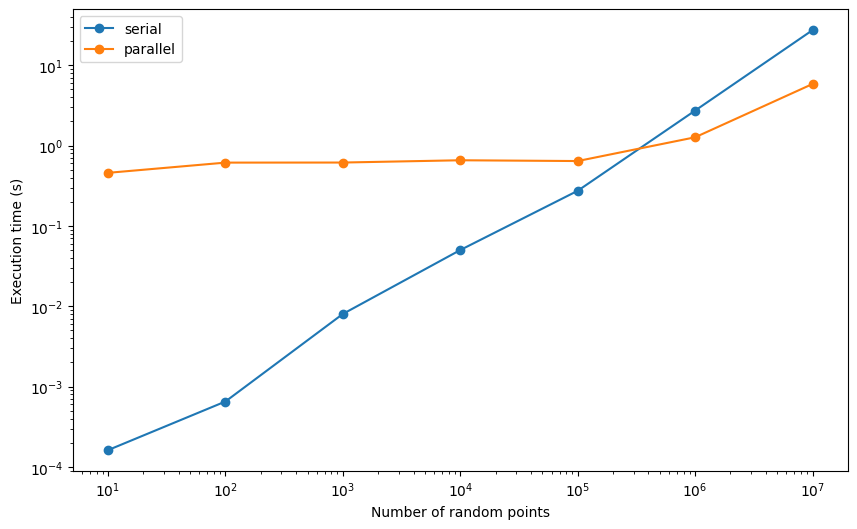

In [15]:
plt.figure(figsize = (10, 6))
plt.plot(n_run, t_serial, '-o', label = 'serial')
plt.plot(n_run, t_parallel, '-o', label = 'parallel')
plt.loglog()
plt.legend()
plt.ylabel('Execution time (s)')
plt.xlabel('Number of random points')
plt.show()

# Exercises (10 pt)

Students get an extra 2 points if exercises are submitted by the end of the lecture.

## Exercise 1 - Muddiest Moment (5 pt)

What was the most confusing part of lecture today?

**Answer here**


## Exercise 2 - Multiprocessing module (5 pt)

In the python module, you have the following function:
```python
def plus_cube(x, y):
    return (x+y)**3
```
Use multiprocessing package to parallel the following code, and record the running time:
```python
for x, y in zip(range(100), range(100)):
    results.append(plus_cube(x, y))
```
**Hint:** You may need to check out the pool.apply function.